<a href="https://colab.research.google.com/github/Farhan1Ahmed1Molla/gold-news-ml-pipeline/blob/main/Gold_News_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install feedparser


import feedparser as fp
import yfinance as yf
import pandas as pd

gold = yf.Ticker("GC=F")
raw_gold = gold.history(period="5y")
print(raw_gold.head())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [feedparser]
                                  Open         High          Low        Close  \
Date                                                                            
2021-11-15 00:00:00-05:00  1872.599976  1873.000000  1858.500000  1866.599976   
2021-11-16 00:00:00-05:00  1864.900024  1879.500000  1851.000000  1854.099976   
2021-11-17 00:00:00-05:00  1851.599976  1870.599976  1851.099976  1870.199951   
2021-11-18 00:00:00-05:00  1869.500000  1873.300049  1856.599976  1861.400024   
2021-11-19 00:00:00-05:00  1860.800049  1868.099976  1844.199951  1851.599976   

                           Volume  Dividends  Stock Splits  
Date                                                        
2021-11-15 00:00:00-05:00  221208        0.0           0.0  
2021-11-16 00:00:00-05:00  220431        0.0           0.0  
2021-11-17 00:00:00-05:00  172417        0.0           0.0  
2021-11-18 00:00:00-05:00  186062        0.0           0.0  
2021-

In [2]:
print(raw_gold.index)

DatetimeIndex(['2021-11-15 00:00:00-05:00', '2021-11-16 00:00:00-05:00',
               '2021-11-17 00:00:00-05:00', '2021-11-18 00:00:00-05:00',
               '2021-11-19 00:00:00-05:00', '2021-11-22 00:00:00-05:00',
               '2021-11-23 00:00:00-05:00', '2021-11-24 00:00:00-05:00',
               '2021-11-26 00:00:00-05:00', '2021-11-29 00:00:00-05:00',
               ...
               '2026-11-02 00:00:00-05:00', '2026-11-03 00:00:00-05:00',
               '2026-11-04 00:00:00-05:00', '2026-11-05 00:00:00-05:00',
               '2026-11-06 00:00:00-05:00', '2026-11-09 00:00:00-05:00',
               '2026-11-10 00:00:00-05:00', '2026-11-11 00:00:00-05:00',
               '2026-11-12 00:00:00-05:00', '2026-11-13 00:00:00-05:00'],
              dtype='datetime64[ns, America/New_York]', name='Date', length=1258, freq=None)


In [3]:
df_gold = raw_gold.reset_index()

df_gold = df_gold[['Date', 'Close']]

df_gold.columns = ['Date', 'Gold_price']

df_gold['Date'] = pd.to_datetime(df_gold['Date'].dt.date)
df_gold['Gold_price'] = df_gold['Gold_price'].round(2)

print(df_gold.head())
print("Total days of Gold data:",  len(df_gold))


        Date  Gold_price
0 2021-11-15      1866.6
1 2021-11-16      1854.1
2 2021-11-17      1870.2
3 2021-11-18      1861.4
4 2021-11-19      1851.6
Total days of Gold data: 1258


In [4]:
rss_url = "https://news.google.com/rss/search?q=gold+price+when:30d&hl=en-US&ceid=US:en"

feed = fp.parse(rss_url)

print(f"HTTP Status: {feed.status} (200 means success)")
print(f"Total articles retrieved: {len(feed.entries)}")

first_item = feed.entries[0]
print("n\available attributes in an entry:", list(first_item.keys()))
print("Sample Title", first_item.title)
print("Sample Raw Date", first_item.published)

HTTP Status: 302 (200 means success)
Total articles retrieved: 100
nvailable attributes in an entry: ['title', 'title_detail', 'links', 'link', 'id', 'guidislink', 'published', 'published_parsed', 'summary', 'summary_detail', 'source']
Sample Title Why Is the Gold Price Falling Even as Investors and Central Banks Pile In? - Morningstar
Sample Raw Date Fri, 30 Oct 2026 07:00:00 GMT


In [5]:
articles = []

for entry in feed.entries:
  articles.append({
      'Date': entry.published,
      'Headline': entry.title
  })

df_news = pd.DataFrame(articles)
df_news['Date'] = pd.to_datetime(df_news['Date']).dt.date
print(df_news.head())



         Date                                           Headline
0  2026-10-30  Why Is the Gold Price Falling Even as Investor...
1  2026-11-13  Gold Price Today | Price of Gold Per Ounce | 2...
2  2026-11-13  Gold price today, Friday, November 13, 2026: G...
3  2026-11-13  Rate-hike bets keep gold on track for worst we...
4  2026-11-12  Gold Price Forecast: Gold Drops Below $4,000 a...


In [6]:
!pip install vaderSentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()

sample_headline = df_news['Headline'].iloc[0]

scores = analyzer.polarity_scores(sample_headline)
print("Headline:", sample_headline)
print("Full Vader Breakdown:", scores)
print("Just the compound score:", scores['compound'])

Headline: Why Is the Gold Price Falling Even as Investors and Central Banks Pile In? - Morningstar
Full Vader Breakdown: {'neg': 0.096, 'neu': 0.904, 'pos': 0.0, 'compound': -0.1531}
Just the compound score: -0.1531


In [7]:
df_news['Sentiment_Score'] = df_news['Headline'].apply(
    lambda headline: analyzer.polarity_scores(headline)['compound'])
print("---Individual Scores---")
print(df_news.head())

daily_sentiment = df_news.groupby('Date').agg(
    Avg_Sentiment=('Sentiment_Score', 'mean'),
    Article_Count=('Headline', 'count')
).reset_index()

daily_sentiment['Avg_Sentiment'] = daily_sentiment['Avg_Sentiment'].round(3)

print("\n--- Daily Summary Table (ready to merge)")
print(daily_sentiment.head())



---Individual Scores---
         Date                                           Headline  \
0  2026-10-30  Why Is the Gold Price Falling Even as Investor...   
1  2026-11-13  Gold Price Today | Price of Gold Per Ounce | 2...   
2  2026-11-13  Gold price today, Friday, November 13, 2026: G...   
3  2026-11-13  Rate-hike bets keep gold on track for worst we...   
4  2026-11-12  Gold Price Forecast: Gold Drops Below $4,000 a...   

   Sentiment_Score  
0          -0.1531  
1           0.0000  
2           0.0000  
3          -0.6249  
4           0.0000  

--- Daily Summary Table (ready to merge)
         Date  Avg_Sentiment  Article_Count
0  2026-10-15          0.000              1
1  2026-10-20          0.039              3
2  2026-10-22         -0.382              1
3  2026-10-23          0.006              2
4  2026-10-26          0.000              1


In [8]:
df_gold['Date'] = pd.to_datetime(df_gold['Date']).dt.date
daily_sentiment['Date'] = pd.to_datetime(daily_sentiment['Date']).dt.date


df_merged = pd.merge(df_gold, daily_sentiment, on='Date', how='left')

df_merged['Article_Count'] = df_merged['Article_Count'].fillna(0)
df_merged['Avg_Sentiment'] = df_merged['Avg_Sentiment'].fillna(0)
df_merged['Tommorow_Price']= df_merged['Gold_price'].shift(-1)

print("---Last 10 Days (Merged AND Shifted) ---")
print(df_merged.tail(10))




---Last 10 Days (Merged AND Shifted) ---
            Date  Gold_price  Avg_Sentiment  Article_Count  Tommorow_Price
1248  2026-11-02      3969.6          0.000            0.0          3940.4
1249  2026-11-03      3940.4          0.000            0.0          4073.0
1250  2026-11-04      4073.0          0.000            0.0          4113.5
1251  2026-11-05      4113.5          0.000            0.0          4074.9
1252  2026-11-06      4074.9          0.000            0.0          4114.5
1253  2026-11-09      4114.5          0.000            0.0          4030.2
1254  2026-11-10      4030.2          0.154            2.0          4000.5
1255  2026-11-11      4000.5          0.001           12.0          3885.3
1256  2026-11-12      3885.3         -0.046           28.0          3887.6
1257  2026-11-13      3887.6         -0.126           46.0             NaN


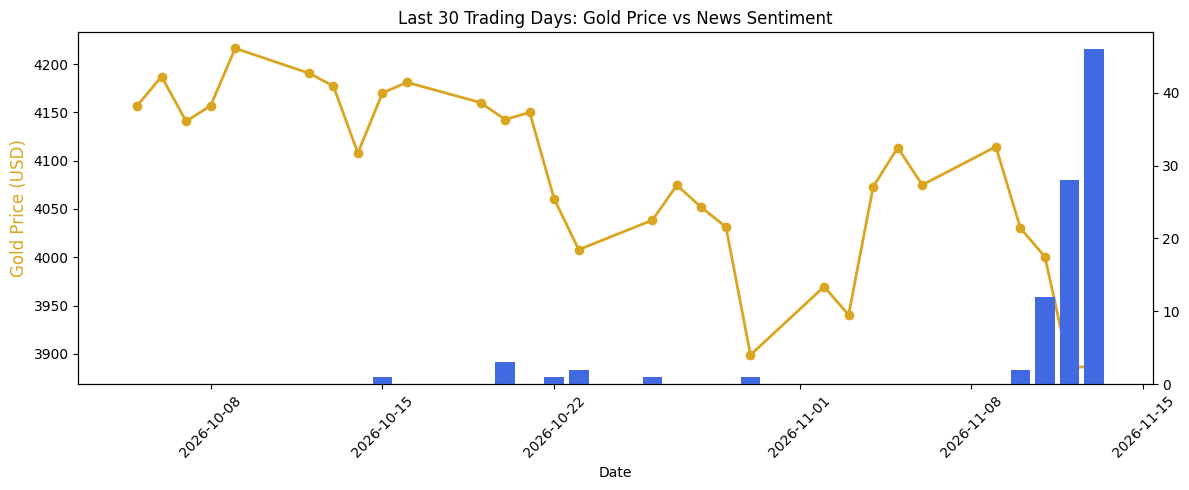

In [9]:
import matplotlib.pyplot as plt

df_last_30 = df_merged.tail(30)

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(df_last_30['Date'], df_last_30['Gold_price'], color='goldenrod', marker='o', linewidth=2, label='Gold Price ($)')
ax1.set_xlabel('Date')
ax1.set_ylabel('Gold Price (USD)', color='goldenrod', fontsize=12)
plt.xticks(rotation=45)

ax2 = ax1.twinx()
ax2.bar(df_last_30['Date'], df_last_30['Article_Count'], color='royalblue', label='News Sentiment')
ax2.axhline(0, color='grey', linestyle='--', linewidth=0.8)

plt.title('Last 30 Trading Days: Gold Price vs News Sentiment')
plt.tight_layout()
plt.show()




In [10]:
features = ["Gold_price", "Avg_Sentiment", "Article_Count"]

historical_data = df_merged.dropna(subset=['Tommorow_Price'])
today_row = df_merged.tail(1)

X = historical_data[features]
y = historical_data['Tommorow_Price']
test_X = today_row[features]

print("Historical rows ready for training (X):", len(X))
print("\nToday's live data for predicting tomorrow (test_X):")
print(test_X)


Historical rows ready for training (X): 1257

Today's live data for predicting tomorrow (test_X):
      Gold_price  Avg_Sentiment  Article_Count
1257      3887.6         -0.126           46.0


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import RandomForestRegressor

train_X, val_X, train_y, val_y = train_test_split(X, y, test_size=0.2, shuffle=False)

rf_model = RandomForestRegressor(random_state=1)
rf_model.fit(train_X, train_y)
rf_preds = rf_model.predict(val_X)
rf_mae = mean_absolute_error(val_y, rf_preds)

lr_model = LinearRegression()
lr_model.fit(train_X, train_y)
lr_preds = lr_model.predict(val_X)
lr_mae = mean_absolute_error(val_y, lr_preds)

print(f"Random Forest Validation MAE:     ${rf_mae:.2f}")
print(f"Linear Regression Validation MAE  ${lr_mae:.2f}")



Random Forest Validation MAE:     $347.79
Linear Regression Validation MAE  $57.39


In [14]:
final_gold_model = LinearRegression()
final_gold_model.fit(X, y)
tommorow_prediction = final_gold_model.predict(test_X)

today_price = test_X['Gold_price'].values[0]
predicted_price = tommorow_prediction[0]
expected_change = predicted_price - today_price

print(f"Today's closing gold price: ${today_price:.2f}")
print(f"Tomorrow's predicted gold price: ${predicted_price:.2f}")
print(f"Expected move: ${expected_change:.2f}")


Today's closing gold price: $3887.60
Tomorrow's predicted gold price: $3825.80
Expected move: $-61.80


In [16]:
for feature_name, weight in zip(features, final_gold_model.coef_):
  print(f"Weight for {feature_name:15}: {weight:.4f}")
print(f"Baseline Intercept (b)    :{final_gold_model.intercept_:.4f}")

Weight for Gold_price     : 0.9993
Weight for Avg_Sentiment  : 17.4032
Weight for Article_Count  : -1.3153
Baseline Intercept (b)    :3.5498


In [18]:
clean_features = ["Gold_price", "Avg_Sentiment"]

X_clean = historical_data[clean_features]

test_X_clean = today_row[clean_features]

clean_model = LinearRegression()
clean_model.fit(X_clean, y)
clean_pred = clean_model.predict(test_X_clean)[0]
clean_Move = clean_pred - today_price

print(f"--- De-Biased Model (Gold_price + Avg_Sentiment Only)---")
print(f"Today's closing gold price: ${today_price:.2f}")
print(f"Tomorrow's predicted gold price: ${clean_pred:.2f}")
print(f"Expected move: ${clean_Move:.2f}")



--- De-Biased Model (Gold_price + Avg_Sentiment Only)---
Today's closing gold price: $3887.60
Tomorrow's predicted gold price: $3885.06
Expected move: $-2.54


In [20]:
forecast_log = pd.DataFrame({
    'Date': [today_row['Date'].values[0]],
    'Today_Gold_price': [today_row['Gold_price'].values[0]],
    'Avg_Sentiment': [today_row['Avg_Sentiment'].values[0]],
    'Article_Count': [today_row['Article_Count'].values[0]],
    'Predicted_Tomorrow_price': [round(clean_pred, 2)],
    'Expected_Move_USD': [round(clean_Move, 2)]
})

forecast_log.to_csv('forecast_log.csv', index=False)

print("Saved_successfully! Here is your official daily forecast log")
print(forecast_log)

Saved_successfully! Here is your official daily forecast log
         Date  Today_Gold_price  Avg_Sentiment  Article_Count  \
0  2026-11-13            3887.6         -0.126           46.0   

   Predicted_Tomorrow_price  Expected_Move_USD  
0                   3885.06              -2.54  
